# Quantum vs. Classical Machine Learning for Financial Prediction — a reproduction

This notebook reproduces **Ahmad, Kashif, Innan & Shafique, *Quantum vs. Classical Machine Learning: A Benchmark Study for Financial Prediction*, arXiv:2601.03802 (2026)**. It is written as a scientific argument: what the paper claims, how we tested it, which alternative explanations we ruled in or out, and what survives.

**How to read it.**
- Every section ends with four short labels: **Observation**, **Inference**, **Remaining uncertainty** and **Claim impact**.
- Cells marked **LIVE** recompute something from the raw data with the code in `lib/`.
- Cells marked **STORED** load the full-scale results. Those runs took about two days of CPU and cannot run interactively. They are read from the durable records in `results/`; each table names its source sweep.
- The whole notebook runs top to bottom on a laptop CPU in a few minutes.

**Labels used throughout.**
- `paper-accurate`: the paper's full protocol with 3–5 seeds.
- `partial`: a reduced protocol.
- `preliminary`: a single tuning seed.
- `diagnostic`: a control that deliberately departs from the paper's protocol.
- `adaptation`: a photonic MerLin version of a paper model. It is not the paper's method.

## Contents

1. [Problem statement and the paper's claims](#1)
2. [Data, splits, metrics and evaluation protocol](#2)
3. [The minimum mathematics](#3)
4. [Known-answer sanity checks](#4)
5. [Model and pipeline walkthrough](#5)
6. [A small live experiment (S&P 500 direction)](#6)
7. [Headline reproduction results](#7)
8. [Fair baseline comparison](#8)
9. [Controls and ablations: leakage, feature timing, GARCH, selection](#9)
10. [Robustness and uncertainty](#10)
11. [Photonic assessment with MerLin](#11)
12. [Claim-level conclusion and limitations](#12)

In [1]:
# Setup: make lib/ (this paper) and runtime_lib/ (the repository) importable, fix seeds and plotting style.
import copy
import json
import platform
import subprocess
import sys
import tempfile
import time
import warnings
from pathlib import Path

PROJECT_DIR = Path.cwd() if (Path.cwd() / "lib" / "runner.py").exists() else Path.cwd() / "papers" / "QML_financial_benchmark"
REPO_ROOT = PROJECT_DIR.parents[1]
sys.path[:0] = [str(REPO_ROOT), str(PROJECT_DIR), str(PROJECT_DIR / "utils")]
DATA_ROOT = str(REPO_ROOT / "data")
RESULTS = PROJECT_DIR / "results"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression

from lib import data, kernels, metrics
from lib import statevector as sv
from lib.models import LSTMClassifier, MLPClassifier, QLSTMClassifier, QNNClassifier, angle_encode, count_parameters
from lib.runner import train_and_evaluate
from lib.tasks.directional import matched_ann_width, qnn_candidates
from runtime_lib.config import deep_update

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
torch.manual_seed(0)
np.random.seed(0)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# One colour per model family, used in every figure.
COLORS = {"QNN": "#2a78d6", "photonic": "#1baf7a", "ANN": "#eb6834", "matched ANN": "#b5446e",
          "logistic": "#6b6b6b", "paper": "#0b0b0b", "GARCH": "#8a5cf6"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
NOTEBOOK_START = time.time()
print("project:", PROJECT_DIR.relative_to(REPO_ROOT))

project: papers/QML_financial_benchmark


<a id="1"></a>
## 1. Problem statement and the paper's claims

The paper asks whether **simulated quantum models outperform classical models of the same family** on three daily equity tasks.

| Task | Prediction | Quantum model | Classical counterpart | Paper tables |
|---|---|---|---|---|
| T1 direction | Will tomorrow's close be above today's? | QNN: 4 families × depth × qubits | Shallow ANN grid | IX (5 Turkish stocks, 3-D), X (S&P 500, 7-D), XI (5 U.S. stocks, 64-D) |
| T2 trading | Long / short / flat signal on the S&P 500 in 4 regimes | QLSTM | LSTM | XII |
| T3 volatility | Next-day 5-day realized variance | Angle or amplitude QSVR | SVR lin/poly/RBF, GARCH(1,1) | XIII, XIV |

**Claims under test.** P marks a primary (abstract) claim and S a secondary one.

| ID | Claim | Paper evidence |
|---|---|---|
| C1 (P) | The hybrid QNN beats the ANN on AAPL, 64-D: AUC 0.635 vs 0.597 | Table XI, single run |
| C2 (P) | The hybrid QNN beats the ANN on KCHOL, 3-D: AUC 0.797 vs 0.748 | Table IX, single run |
| C3 (S) | The ANN wins on most other directional tasks; QNNs have higher recall | Tables IX–XI |
| C4 (S) | Hybrid preprocessing and multi-qubit readout drive QNN performance | Selected architectures only |
| C5 (P) | The QLSTM has a higher Sharpe than the LSTM in F1 (2008–09) and F2 (2018–19) | Table XII, single run per regime |
| C6 (S) | The QLSTM has a slightly higher AUC in all regimes | Table XII |
| C7 (P) | The angle QSVR has the lowest QLIKE on KCHOL and is within 0.02–0.04 of RBF elsewhere | Table XIII |
| C8 (S) | The angle QSVR beats linear and polynomial SVR on all 4 tickers | Table XIII |
| C9 (S) | The amplitude QSVR is competitive at d = 32 and degrades at d = 64 | Table XIV and text |
| C10 (S) | QSVRs match or exceed linear SVRs | Conclusion |
| C11 | The benchmark is fair: aligned splits, matched budgets, leak-free validation | §III |

**Falsifiable research question.** On the paper's tasks, does any quantum model beat its classical counterpart on held-out test data under three conditions?
- features available at prediction time only;
- several training seeds;
- classical controls with the same inputs, comparable parameter counts and equal tuning effort.

**What would weaken the claims:**
- quantum − classical differences whose 95% confidence interval contains 0 (ties);
- classical models significantly ahead;
- the paper's numbers reachable only with information unavailable at prediction time;
- the paper's comparisons falling inside the noise of the evaluation protocol.

<a id="2"></a>
## 2. Data, splits, metrics and evaluation protocol

**Data.** Yahoo Finance daily prices are the paper's source.
- `utils/download_yahoo_data.py` fetched 18 symbols for 2000–2024 into `data/QML_financial_benchmark/yahoo_daily_prices/`, with SHA-256 checksums in `manifest.json`.
- This is a **later snapshot** than the paper's undated download. Adjusted prices are revised over time, so exact numerical agreement is not expected. The check below shows that the S&P 500 series matches the paper's Table VI.

In [2]:
# LIVE: data provenance and a check against the paper's Table VI (S&P 500 regime statistics).
manifest = json.loads((REPO_ROOT / "data/QML_financial_benchmark/yahoo_daily_prices/manifest.json").read_text())
print("fetched:", manifest["fetched_at_utc"], "| symbols:", len(manifest["symbols"]))

gspc = data.load_price_series("^GSPC", DATA_ROOT)
regimes = json.loads((PROJECT_DIR / "configs/e5_original.json").read_text())["trading"]["dataset"]["regimes"]
paper_table_vi = {"F1": (34.9, -53.3, -0.12), "F2": (15.0, -19.8, -0.61), "F3": (26.2, -33.9, -1.05)}
rows = []
for regime, (paper_sigma, paper_drawdown, paper_skew) in paper_table_vi.items():
    prices = gspc.loc[regimes[regime][0]:regimes[regime][1]]
    returns = np.log(prices / prices.shift(1)).dropna()  # the paper's statistics use daily log returns
    rows.append({
        "regime": regime,
        "sigma_ann % (ours)": 100 * returns.std() * np.sqrt(252), "sigma_ann % (paper)": paper_sigma,
        "max drawdown % (ours)": 100 * (prices / prices.cummax() - 1).min(), "max drawdown % (paper)": paper_drawdown,
        "skew (ours)": returns.skew(), "skew (paper)": paper_skew,
    })
table_vi = pd.DataFrame(rows).set_index("regime")
table_vi.round(2)

fetched: 2026-10-21T08:32:15+00:00 | symbols: 18


,sigma_ann % (ours),sigma_ann % (paper),max drawdown % (ours),max drawdown % (paper),skew (ours),skew (paper)
regime,,,,,,
F1,34.90,34.9,-53.25,-53.3,-0.12,-0.12
F2,14.99,15.0,-19.78,-19.8,-0.61,-0.61
F3,26.24,26.2,-33.92,-33.9,-1.05,-1.05


**Observation.** Annualized volatility, maximum drawdown and skew of daily log returns agree with Table VI to within 0.15 percentage points (σ) and 0.01 (skew) in F1–F3.
**Inference.** Our S&P 500 series is the paper's series. Later snapshot drift is not a plausible cause of large gaps on this index.
**Remaining uncertainty.** Turkish and single-stock adjusted prices may have drifted more; we cannot check them, because the paper prints no statistics for them.

### Splits

- **T1 (direction).** Expanding walk-forward folds (the paper's Fig. 4).
  - Fold *k* trains on everything before its boundary and validates on the next 2 years.
  - **Fold 5 (2020–2021) is the test set.**
  - We select models on the mean validation AUC of **folds 1–4 (`leak_free`, our primary protocol)**.
  - The paper averages folds 1–5, which includes the test window. We report that protocol too, labelled `paper`.
  - The last 10% of each training window is held out for early stopping, so no fold stops on its own validation data.
- **T2 (trading).** The paper's Fig. 6 design. Models train on the history before a regime (cut 70/10/10/10 into train / early-stop / model-select / threshold-calibration), then trade the **whole regime** out of sample.
- **T3 (volatility).** An expanding window: 720 initial days, refit every 120 days, test 2007–2024 (about 4,300 days). Optuna tunes each SVR/QSVR on the last 20% of each training window.

In [3]:
# LIVE: the T1 walk-forward folds, built by lib/data.py from the default (KCHOL 3-D) config.
defaults = json.loads((PROJECT_DIR / "configs/defaults.json").read_text())
kchol_dataset = defaults["directional"]["dataset"]
kchol = data.build_directional_frame(kchol_dataset, DATA_ROOT)
folds = data.walk_forward_folds(kchol.index, kchol_dataset)
fold_table = pd.DataFrame([{
    "fold": fold.number,
    "train": f"{kchol.index[fold.train[0]].date()} → {kchol.index[fold.train[-1]].date()}",
    "early stop": f"{kchol.index[fold.early_stop[0]].date()} → {kchol.index[fold.early_stop[-1]].date()}",
    "validation / test": f"{kchol.index[fold.validation[0]].date()} → {kchol.index[fold.validation[-1]].date()}",
    "role": "TEST (never used for selection in leak_free)" if fold.number == 5 else "selection",
} for fold in folds]).set_index("fold")
print(f"KCHOL.IS 3-D frame: {len(kchol)} rows, features {list(kchol.columns[:-1])}, up-day rate {kchol['label'].mean():.3f}")
fold_table

KCHOL.IS 3-D frame: 3249 rows, features ['rsi14', 'pct_k14', 'pct_k14_sma3'], up-day rate 0.484


,train,early stop,validation / test,role
fold,,,,
1,2009-01-07 → 2011-09-12,2011-09-13 → 2011-12-30,2012-01-02 → 2013-12-31,selection
2,2009-01-07 → 2013-06-24,2013-06-25 → 2013-12-31,2014-01-02 → 2015-12-31,selection
3,2009-01-07 → 2015-04-20,2015-04-21 → 2015-12-31,2016-01-04 → 2017-12-29,selection
4,2009-01-07 → 2017-02-08,2017-02-09 → 2017-12-29,2018-01-02 → 2019-12-31,selection
5,2009-01-07 → 2018-11-23,2018-11-26 → 2019-12-31,2020-01-02 → 2021-12-31,TEST (never used for selection in leak_free)


### Metrics

- **T1: test AUC** (primary; threshold-free), plus accuracy, precision and recall. An AUC of 0.5 is chance level.
- **T2: annualized Sharpe ratio** of the daily strategy returns after a 0.05% fee per position change, plus test AUC. A position is long when the score is above τ_long, short when it is below τ_short, and flat otherwise. τ is calibrated on a held-out slice to maximize Sharpe.
- **T3: QLIKE**, lower is better:

$$\mathrm{QLIKE}=\frac{1}{T}\sum_t\Big[\log \widehat{RV}_{t+1}+\frac{RV_{t+1}}{\widehat{RV}_{t+1}}\Big],\qquad RV_{t+1}=\frac{1}{5}\sum_{i=-3}^{1} r_{t+i}^2 .$$

Four of the five squared returns in $RV_{t+1}$ are **already known at time t**. Section 9 shows this matters.

**Statistics.**
- T1–T2: quantum − control differences, with seed-level t-tests and 95% intervals.
- T3: Diebold–Mariano tests on the QLIKE loss differential.
- "Tie" means p ≥ 0.05.

<a id="3"></a>
## 3. The minimum mathematics

**QNN (T1).** Features $x\in[0,1]^d$ are encoded into an $n$-qubit state in one of two ways:
- by angle, $|\psi(x)\rangle=\bigotimes_k R_Y(\pi x_k)|0\rangle$;
- by amplitude, $|\psi(x)\rangle = x/\lVert x\rVert$ on $\log_2 d$ qubits.

Hybrid families first apply a trainable $\mathrm{Linear}(d\to k)$. A variational ansatz follows: $L$ layers of $R_Z R_Y R_Z$ rotations and CZ entanglers, so $3nL$ parameters. The readout is one of two:
- **single-qubit (SQ):** $p=(1+\langle Z_{n}\rangle)/2$;
- **multi-qubit (MQ):** $\mathrm{Linear}(\langle Z_1\rangle,\dots,\langle Z_n\rangle)$.

**QLSTM (T2).** This is Chen et al. (2020)'s LSTM with each gate replaced by a variational circuit. The paper does not give the layout; we reconstructed it from the four parameter counts in Table XII (checked in Section 4).

**QSVR (T3).** An SVR with a precomputed fidelity kernel

$$K(x,x')=|\langle\psi(x)|\psi(x')\rangle|^{2\beta}.$$

**A key identity (amplitude kernel).** The paper's amplitude feature map applies fixed random unitaries $U$ after encoding. But

$$|\langle\psi(x)|U^\dagger U|\psi(x')\rangle|^2=|\langle\psi(x)|\psi(x')\rangle|^2=\Big(\tfrac{x\cdot x'}{\lVert x\rVert\lVert x'\rVert}\Big)^2 ,$$

so this "quantum" kernel is the squared cosine similarity: a **classical** kernel on any platform. The same holds for any data-independent layer placed after the last encoding. Depth only matters when the data is re-uploaded between layers.

**GARCH(1,1) (T3 baseline).** It produces the one-day variance $\sigma^2_{t+1}=\omega+\alpha\varepsilon_t^2+\beta\sigma_t^2$. The target $RV_{t+1}$ spans 5 days, four of them already known. We therefore compare two versions:
- the paper's (most likely) forecast, $\widehat{RV}_{t+1}=\sigma^2_{t+1}$ (`garch_sigma2`);
- the **completed** forecast, $\widehat{RV}_{t+1}=\big(\sum_{i=0}^{3}r_{t-i}^2+\sigma^2_{t+1}\big)/5$ (`garch`).

<a id="4"></a>
## 4. Known-answer sanity checks

Before trusting any comparison we check the building blocks against answers known in closed form. **These checks validate components; they are not an end-to-end reproduction.**

In [4]:
# LIVE: four known-answer checks on lib/ components.
checks = {}

# (a) Statevector simulator: R_Y(theta)|0> gives <Z> = cos(theta) on every qubit.
theta = torch.linspace(0, np.pi, 7, dtype=torch.float64)
expectation = sv.expectation_z(angle_encode(theta.repeat(3, 1).T))
checks["(a) <Z> of RY(θ)|0> = cos θ"] = float((expectation - torch.cos(theta)[:, None]).abs().max())

# (b) Amplitude kernel: any Haar-random unitary after amplitude encoding leaves the kernel unchanged,
#     and the kernel equals the squared cosine similarity computed by lib/kernels.py.
generator = torch.Generator().manual_seed(0)
x = torch.rand(6, 32, dtype=torch.float64, generator=generator)
unitary = sv.haar_random_unitary(32, generator, torch.float64)
states = sv.flatten(sv.amplitude_state(x, 5)) @ unitary.T
fidelity = kernels.fidelity_kernel(states, states)
checks["(b) amplitude kernel = cos² similarity"] = float(np.abs(fidelity - kernels.amplitude_kernel(x.numpy(), x.numpy(), beta=1)).max())

# (c) Angle kernel with no entangling layer = product of cos²(π(x_k - x'_k)/2).
x_unit = np.random.default_rng(1).uniform(size=(5, 4))
product_state_kernel = kernels.fidelity_kernel(*(kernels.angle_feature_states(x_unit, 0, "ring", np.pi, 1234),) * 2)
closed_form = np.prod(np.cos(np.pi * (x_unit[:, None, :] - x_unit[None, :, :]) / 2) ** 2, axis=-1)
checks["(c) L=0 angle kernel = Π cos²"] = float(np.abs(product_state_kernel - closed_form).max())

# (d) QLIKE is minimized by the true variance: QLIKE(rv, rv) = log(rv) + 1.
rv = np.array([1e-4, 4e-4])
checks["(d) QLIKE(rv, rv) = log rv + 1"] = float(np.abs(metrics.qlike(rv, rv) - (np.log(rv) + 1)).max())

pd.Series(checks, name="max absolute error").to_frame()

,max absolute error
(a) <Z> of RY(θ)|0> = cos θ,1.6081e-16
(b) amplitude kernel = cos² similarity,1.3323e-15
(c) L=0 angle kernel = Π cos²,6.6613e-16
"(d) QLIKE(rv, rv) = log rv + 1",0.0000e+00


In [5]:
# LIVE: parameter counts pin down the QLSTM layout the paper does not describe (Table XII, d = 4 inputs).
paper_qlstm_counts = [233, 476, 386, 656]
found = {count_parameters(QLSTMClassifier(4, q, L)): (q, L) for q in (3, 4, 5) for L in range(1, 7)}
qlstm_check = pd.DataFrame([{"Table XII QLSTM parameters": n, "reproduced by (qubits, layers)": found.get(n, "none")}
                            for n in paper_qlstm_counts])
lstm_check = pd.DataFrame([{"Table XII LSTM parameters": n, "nn.LSTM + Linear (hidden, layers)":
                            next((h, L) for h in (3, 4, 5) for L in range(1, 7) if count_parameters(LSTMClassifier(4, h, L)) == n)}
                           for n in (325, 1426)])
display(qlstm_check, lstm_check)

,Table XII QLSTM parameters,"reproduced by (qubits, layers)"
0,233,"(4, 2)"
1,476,"(5, 4)"
2,386,"(5, 3)"
3,656,"(5, 6)"


,Table XII LSTM parameters,"nn.LSTM + Linear (hidden, layers)"
0,325,"(4, 2)"
1,1426,"(5, 6)"


**Observation.**
- The simulator, the amplitude-kernel identity, the product-state kernel and QLIKE all match their closed forms to machine precision.
- All four of the paper's QLSTM parameter counts are reproduced exactly by one consistent layout.
- The LSTM counts match PyTorch's `nn.LSTM` plus a linear head.

**Inference.**
- The components compute what the equations say.
- Check (b) proves that the paper's amplitude QSVR (Table XIV) is a classical cosine kernel. Comparing it to an SVR therefore compares two classical kernels.

**Remaining uncertainty.** None for these components. Matching parameter counts fix the QLSTM layout up to the ordering of equivalent gates.

**Claim impact.** C9 ("amplitude QSVR is competitive") is reframed: the comparison it describes contains no quantum resource.

<a id="5"></a>
## 5. Model and pipeline walkthrough

**One T1 run** (`lib/tasks/directional.py::run_directional`):
1. Build the features and label.
2. Build the 5 folds.
3. Train every QNN and ANN candidate on every fold:
   - Adam, lr 1e-3, batch 32;
   - at most 300 epochs;
   - early stopping with patience 30 on the early-stop AUC.
4. Select one QNN and one ANN per protocol by mean validation AUC.
5. Evaluate the selected models on fold 5.
6. Add three controls on the same test rows:
   - an ANN with the **selected QNN's parameter count**: the closest achievable one-hidden-layer width, within ±10% in 62 of 67 pairs and up to +24% in the rest;
   - logistic regression;
   - majority class.

Every candidate's validation score is written to `candidates.csv` and every test metric to `metrics.json`.

In [6]:
# LIVE: the T1 candidate grid for the S&P 500 7-D task and the size of each QNN family.
e2_config = json.loads((PROJECT_DIR / "configs/e2_original.json").read_text())
qnn_cfg = deep_update(copy.deepcopy(defaults["directional"]["models"]["qnn"]), e2_config["directional"]["models"]["qnn"])
grid = pd.DataFrame(qnn_candidates(qnn_cfg, n_features=7))
print(f"E2 grid: {len(grid)} QNN candidates + {len(e2_config['directional']['models']['ann']['hidden_layer_options'])} ANN widths, each trained on 5 folds")

family_sizes = []
for family, hybrid, multi in [("SQ", False, False), ("MQ", False, True), ("Hybrid-SQ", True, False), ("Hybrid-MQ", True, True)]:
    model = QNNClassifier(7, 7, layers=3, hybrid=hybrid, multi_qubit_readout=multi, encoding="angle", angle_scale=np.pi)
    budget = count_parameters(model)
    width = matched_ann_width(budget, 7)
    family_sizes.append({"family (L=3, 7 qubits)": family, "QNN parameters": budget,
                         "matched ANN [7-w-1] width": width,
                         "matched ANN parameters": count_parameters(MLPClassifier(7, [width]))})
batch = torch.rand(4, 7)
print("forward pass: input", tuple(batch.shape), "→ logits", tuple(model(batch).shape))
pd.DataFrame(family_sizes)

E2 grid: 24 QNN candidates + 10 ANN widths, each trained on 5 folds
forward pass: input (4, 7) → logits (4,)


,"family (L=3, 7 qubits)",QNN parameters,matched ANN [7-w-1] width,matched ANN parameters
0,SQ,63,7,64
1,MQ,71,8,73
2,Hybrid-SQ,119,13,118
3,Hybrid-MQ,127,14,127


**Observation.** A 7-qubit QNN at depth 3 has 63–127 parameters, far fewer than the paper's [7–32–16–1] ANN (801). The matched ANN pairs each selected QNN with the one-hidden-layer ANN whose parameter count is closest. That is within 10% in 62 of 67 pairs. The other 5 are small QNNs or 64-D inputs, where one extra hidden unit adds d + 2 parameters.

**Inference.** The paper compares models of very different sizes. Parameter count is a dimension we can and do match. Below, "matched" refers **only** to parameter count, unless another dimension is named.

<a id="6"></a>
## 6. A small live experiment: S&P 500 direction (Table X)

We rerun the E2 protocol end to end through the same runner the sweeps used (`lib/runner.py::train_and_evaluate`). It is **reduced** to fit a few minutes of CPU:
- one QNN family (Hybrid-SQ, 7 qubits, L = 2);
- one ANN width ([7–8–1]);
- at most 30 epochs;
- 3 seeds.

The full sweep S6 used the 24 QNN × 10 ANN grid, 300 epochs and 5 seeds. **This run shows the pipeline working on real data; the headline numbers in Section 7 come from the full sweep.**

In [7]:
# LIVE: reduced E2 run, 3 seeds, through the production runner (about 3 minutes on a laptop CPU).
LIVE_SEEDS = [0, 1, 2]
live_overlay = {"directional": {"models": {"qnn": {"families": ["Hybrid-SQ"], "layers": [2]},
                                           "ann": {"hidden_layer_options": [[8]]}},
                                "training": {"max_epochs": 30}}}

def resolved_config(overlay, seed):
    cfg = deep_update(copy.deepcopy(defaults), copy.deepcopy(overlay))
    return deep_update(cfg, {"seed": seed, "data_root": DATA_ROOT, "num_threads": 4})

live_rows, live_start = [], time.time()
for seed in LIVE_SEEDS:
    cfg = deep_update(resolved_config(e2_config, seed), live_overlay)
    with tempfile.TemporaryDirectory() as run_dir:
        (Path(run_dir) / "config_snapshot.json").write_text(json.dumps(cfg))  # written by the shared runtime in normal runs
        train_and_evaluate(cfg, Path(run_dir))
        test = json.loads((Path(run_dir) / "metrics.json").read_text())["test"]
    for key, label in [("leak_free:qnn", "QNN"), ("leak_free:ann", "ANN"), ("leak_free:ann_parameter_matched", "matched ANN"), ("logistic_regression", "logistic")]:
        live_rows.append({"seed": seed, "model": label, "test AUC": test[key]["auc"], "parameters": test[key]["parameters"]})
live = pd.DataFrame(live_rows)
print(f"live run time: {time.time() - live_start:.0f} s")
live.pivot(index="seed", columns="model", values="test AUC").round(3)

live run time: 183 s


model,ANN,QNN,logistic,matched ANN
seed,,,,
0,0.758,0.755,0.767,0.748
1,0.769,0.703,0.767,0.737
2,0.767,0.749,0.767,0.770


In [8]:
# STORED vs LIVE: the same models from the full S6 sweep (5 seeds, full grid, 300 epochs).
per_seed = pd.read_csv(RESULTS / "directional_per_seed_test.csv")
MODEL_LABELS = {"leak_free:qnn": "QNN", "leak_free:ann": "ANN", "leak_free:ann_parameter_matched": "matched ANN", "logistic_regression": "logistic"}
full_e2 = per_seed[(per_seed.sweep_id == "e2_spx") & per_seed.model.isin(MODEL_LABELS)].assign(model=lambda f: f.model.map(MODEL_LABELS))
summary = pd.DataFrame({
    "live reduced (3 seeds)": live.groupby("model")["test AUC"].agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}"),
    "full sweep S6 (5 seeds)": full_e2.groupby("model")["auc"].agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}"),
})
summary.loc["QNN", "paper Table X"] = "0.750"
summary.loc["ANN", "paper Table X"] = "0.766"
summary.fillna("—")

,live reduced (3 seeds),full sweep S6 (5 seeds),paper Table X
model,,,
ANN,0.765 ± 0.006,0.757 ± 0.012,0.766
QNN,0.736 ± 0.029,0.757 ± 0.008,0.750
logistic,0.767 ± 0.000,0.767 ± 0.000,—
matched ANN,0.752 ± 0.017,0.760 ± 0.020,—


**Observation.**
- Even the reduced live run lands near the paper's S&P 500 AUCs (0.75–0.77). The logistic regression reaches about 0.767 with 8 parameters.
- The full sweep gives a QNN of 0.757 ± 0.008 and an ANN of 0.757 ± 0.012.

**Inference.**
- The pipeline reproduces Table X's level.
- The predictive signal is the same-day Asian and European index returns. A linear model captures it.

**Remaining uncertainty.**
- The live run uses a reduced grid and fewer epochs, so its QNN number can be a little lower and more variable than the full sweep's.
- Seed-to-seed spread is visible even here.

**Claim impact.** Table X **reproduces** quantitatively. The QNN and ANN tie (Section 7).

<a id="7"></a>
## 7. Headline reproduction results

### 7.1 Task 1: the two abstract claims (C1, C2) and the reproduced E2

Each dot is one seed's fold-5 test AUC. Black stars are the paper's single-run values. All local models are selected with the `leak_free` protocol.

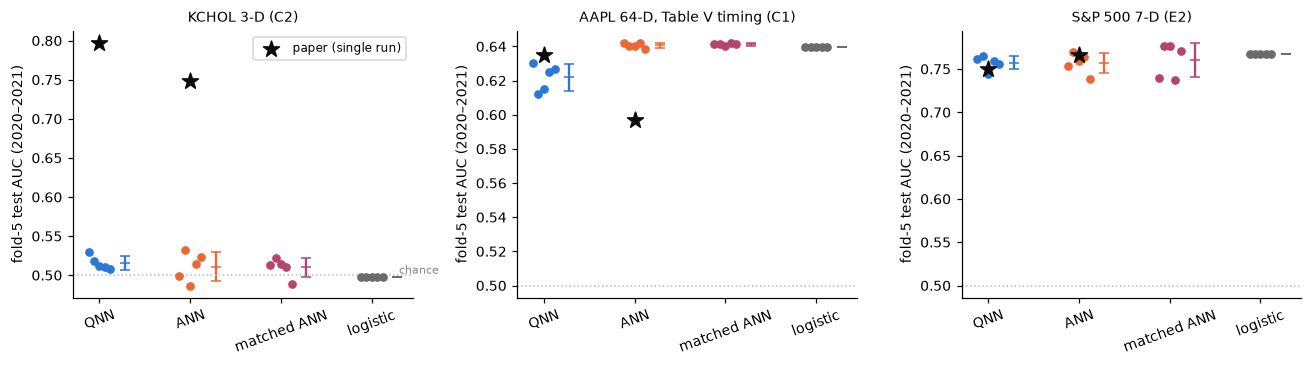

model,ANN,QNN,logistic,matched ANN
setting,,,,
"AAPL 64-D, Table V timing (C1)",0.641,0.622,0.640,0.641
KCHOL 3-D (C2),0.511,0.516,0.498,0.510
S&P 500 7-D (E2),0.757,0.757,0.767,0.760


In [9]:
# STORED: per-seed test AUCs from sweeps S1 (KCHOL), S12a (AAPL, Table V timing) and S6 (S&P 500).
HEADLINE = [("e1_kchol_2", "KCHOL 3-D (C2)", (0.797, 0.748)),
            ("e3_tablev_aapl", "AAPL 64-D, Table V timing (C1)", (0.635, 0.597)),
            ("e2_spx", "S&P 500 7-D (E2)", (0.750, 0.766))]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
headline_rows = []
for axis, (sweep, title, (paper_qnn, paper_ann)) in zip(axes, HEADLINE):
    rows = per_seed[(per_seed.sweep_id == sweep) & per_seed.model.isin(MODEL_LABELS)].assign(model=lambda f: f.model.map(MODEL_LABELS))
    for position, label in enumerate(MODEL_LABELS.values()):
        values = rows.loc[rows.model == label, "auc"]
        axis.scatter(np.full(len(values), position) + np.linspace(-0.12, 0.12, len(values)), values,
                     color=COLORS[label], s=22, zorder=3)
        axis.errorbar(position + 0.28, values.mean(), yerr=values.std(), fmt="_", color=COLORS[label], capsize=3)
        headline_rows.append({"setting": title, "model": label, "seeds": len(values), "mean": values.mean(), "std": values.std()})
    axis.scatter([0, 1], [paper_qnn, paper_ann], marker="*", s=120, color=COLORS["paper"], zorder=4, label="paper (single run)")
    axis.axhline(0.5, color="#bbbbbb", linestyle=":", linewidth=1)
    axis.set_xticks(range(4), list(MODEL_LABELS.values()), rotation=20)
    axis.set_title(title, fontsize=9)
    axis.set_ylabel("fold-5 test AUC (2020–2021)")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].annotate("chance", (3.3, 0.502), fontsize=7, color="#888888")
fig.tight_layout()
plt.show()
pd.DataFrame(headline_rows).pivot(index="setting", columns="model", values="mean").round(3)

In [10]:
# STORED: quantum − control differences with seed-level 95% intervals (results/phase5_differences.csv).
differences = pd.read_csv(RESULTS / "phase5_differences.csv")
headline_settings = ["KCHOL 3-D lagged", "AAPL 64-D Table V timing", "S&P 500 7-D"]
wanted = ["leak_free:qnn - leak_free:ann", "leak_free:qnn - leak_free:ann_parameter_matched", "leak_free:qnn - logistic_regression"]
(differences[differences.setting.isin(headline_settings) & differences.comparison.isin(wanted) & (differences.model == "QNN")]
 [["setting", "comparison", "difference", "ci_low", "ci_high", "p_value"]].round(4).reset_index(drop=True))

,setting,comparison,difference,ci_low,ci_high,p_value
0,KCHOL 3-D lagged,leak_free:qnn - leak_free:ann,0.0045,-0.0231,0.0321,0.6744
1,KCHOL 3-D lagged,leak_free:qnn - leak_free:ann_parameter_matched,0.0056,-0.0086,0.0198,0.3379
2,KCHOL 3-D lagged,leak_free:qnn - logistic_regression,0.0173,0.0062,0.0285,0.0124
3,S&P 500 7-D,leak_free:qnn - leak_free:ann,0.0005,-0.0149,0.0158,0.9338
4,S&P 500 7-D,leak_free:qnn - leak_free:ann_parameter_matched,-0.0028,-0.0326,0.0271,0.8086
5,S&P 500 7-D,leak_free:qnn - logistic_regression,-0.0100,-0.0199,-0.0001,0.0487
6,AAPL 64-D Table V timing,leak_free:qnn - leak_free:ann,-0.0186,-0.0282,-0.0091,0.0056
7,AAPL 64-D Table V timing,leak_free:qnn - leak_free:ann_parameter_matched,-0.0193,-0.0288,-0.0098,0.0049
8,AAPL 64-D Table V timing,leak_free:qnn - logistic_regression,-0.0178,-0.0276,-0.0079,0.0075


**Observation.**
- **KCHOL (C2):** every model sits at chance level (AUC ≈ 0.51). The paper's 0.797 and 0.748 are far outside the seed spread.
- **AAPL (C1):** with the paper's likely feature timing, the absolute AUCs match (QNN 0.622, paper 0.635). But the ANN, the parameter-matched ANN and logistic regression are all **above** the QNN, by −0.019 AUC with a 95% CI of [−0.029, −0.010] and p = 0.005.
- **S&P 500:** QNN and ANN tie at the paper's level.

**Inference.**
- C1 and C2 do not hold once seeds and comparable controls are used.
- KCHOL needs a separate explanation, because even the paper's ANN number (0.748) is unreachable here. Section 9 tests leakage.

**Remaining uncertainty.**
- The test is a single 2-year window.
- The exact feature construction of the paper is unknown.

**Claim impact.**
- C1: **contradicted** (direction reversed).
- C2: **not reproduced**; Section 9 gives the cause.
- E2: **reproduced**.

### 7.2 All Task 1 settings against the paper (Tables IX–XI)

The table below is generated by `utils/paper_vs_reproduced.py` from the stored metrics. Its columns:
- **delta** is reproduced − paper;
- **metric agreement** is "yes" if |delta| ≤ max(0.02, 2 × seed std);
- **trend agreement** asks whether the local QNN − ANN difference has the paper's sign at p < 0.05.

In [11]:
# STORED: paper vs reproduced, every Task 1 row.
paper_vs = pd.read_csv(RESULTS / "paper_vs_reproduced.csv")
columns = ["paper_item", "claim", "setting", "model", "paper_value", "reproduced_mean", "reproduced_std", "delta",
           "metric_agreement", "trend_agreement", "claim_support", "seeds"]
paper_vs[paper_vs.metric == "test AUC (max)"][columns].round(3).reset_index(drop=True)

,paper_item,claim,setting,model,paper_value,reproduced_mean,reproduced_std,delta,metric_agreement,trend_agreement,claim_support,seeds
0,Table IX,C2,KCHOL 3-D lagged,QNN,0.797,0.516,0.009,-0.281,no,tie,UNSUPPORTED,5
1,Table IX,C2,KCHOL 3-D lagged,ANN,0.748,0.511,0.018,-0.236,no,tie,UNSUPPORTED,5
2,Table IX,C2,KCHOL 3-D same-day (diagnostic),QNN,0.797,0.926,0.011,0.129,n/a (diagnostic features),reversed,UNSUPPORTED,5
3,Table IX,C2,KCHOL 3-D same-day (diagnostic),ANN,0.748,0.944,0.003,0.197,n/a (diagnostic features),reversed,UNSUPPORTED,5
4,Table IX,C3,GARAN 3-D lagged,QNN,0.709,0.497,0.023,-0.213,no,tie,PARTIALLY_SUPPORTED,5
5,Table IX,C3,GARAN 3-D lagged,ANN,0.810,0.515,0.015,-0.295,no,tie,PARTIALLY_SUPPORTED,5
6,Table IX,C3,TCELL 3-D lagged,QNN,0.743,0.507,0.010,-0.236,no,tie,PARTIALLY_SUPPORTED,5
7,Table IX,C3,TCELL 3-D lagged,ANN,0.760,0.492,0.010,-0.267,no,tie,PARTIALLY_SUPPORTED,5
8,Table IX,C3,TUPRS 3-D lagged,QNN,0.904,0.469,0.022,-0.435,no,tie,PARTIALLY_SUPPORTED,5
9,Table IX,C3,TUPRS 3-D lagged,ANN,0.904,0.498,0.024,-0.406,no,tie,PARTIALLY_SUPPORTED,5


**Observation.**
- The metric agrees only for S&P 500 and for the AAPL QNN under the Table V timing.
- Every Turkish and strictly lagged U.S. setting is at chance level, 0.1–0.4 AUC below the paper.
- No setting shows the QNN significantly above the ANN in the paper's direction.
- BA's reversal ("QNN > ANN grid") disappears against the matched ANN and logistic regression (Section 8).

**Inference.** Where the features carry signal, local and paper levels agree. Where they do not, the paper's levels require information that our leak-free pipeline does not use (Section 9).

**Claim impact.** C3 ("classical wins elsewhere") is **partially supported**: the classical side never loses, but it rarely wins significantly either.

### 7.3 Task 2: trading Sharpe (Table XII) — `partial`

**The reduction.** The 30-candidate grid was searched on seed 0 only (selection by model-select AUC). The selected models were retrained on seeds 1–4. This captures training noise but **not** selection noise.

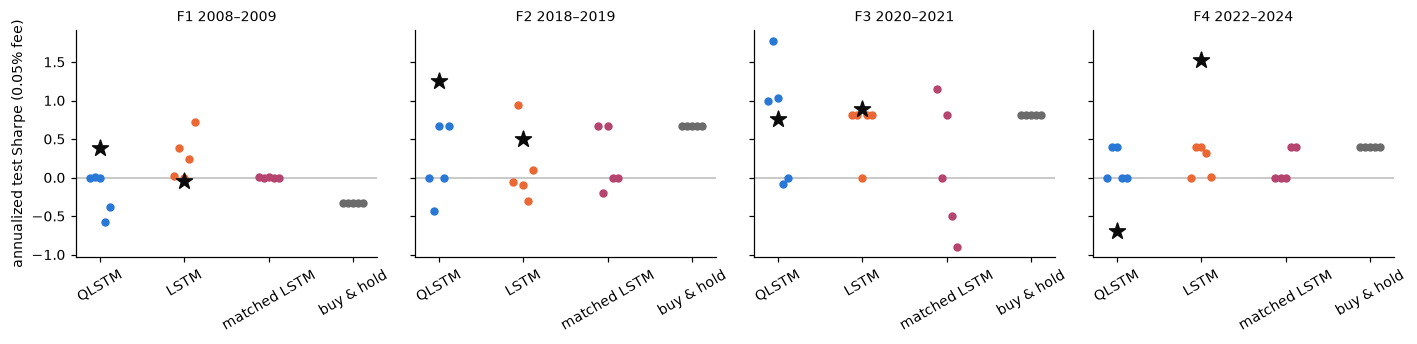

mean                                                        std                                                      count  \
model  auc:lstm auc:lstm_parameter_matched auc:qlstm buy_and_hold auc:lstm auc:lstm_parameter_matched auc:qlstm buy_and_hold auc:lstm   
regime                                                                                                                                  
F1         0.27                       0.00     -0.19        -0.33     0.30                       0.00      0.27          0.0        5   
F2         0.12                       0.23      0.18         0.66     0.48                       0.41      0.48          0.0        5   
F3         0.65                       0.11      0.74         0.82     0.37                       0.87      0.78          0.0        5   
F4         0.23                       0.16      0.16         0.40     0.21                       0.22      0.22          0.0        5   

                                                          
model  auc:lstm_parameter_matched auc:qlstm buy_and_hold  
regime                                                    
F1                              5         5            5  
F2                              5         5            5  
F3                              5         5            5  
F4                              5         5            5

In [12]:
# STORED: per-seed test Sharpe per regime (sweeps S4, S9, S11), paper values as stars.
trading = pd.read_csv(RESULTS / "e5_trading_per_seed.csv")
paper_sharpe = {"F1": (0.3865, -0.0477), "F2": (1.2585, 0.4966), "F3": (0.7659, 0.8947), "F4": (-0.6936, 1.5228)}
models_t2 = {"auc:qlstm": ("QLSTM", COLORS["QNN"]), "auc:lstm": ("LSTM", COLORS["ANN"]),
             "auc:lstm_parameter_matched": ("matched LSTM", COLORS["matched ANN"]), "buy_and_hold": ("buy & hold", COLORS["logistic"])}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for axis, regime in zip(axes, ["F1", "F2", "F3", "F4"]):
    for position, (model, (label, color)) in enumerate(models_t2.items()):
        values = trading[(trading.regime == regime) & (trading.model == model)]["sharpe"]
        axis.scatter(np.full(len(values), position) + np.linspace(-0.12, 0.12, len(values)), values, color=color, s=20, zorder=3)
    axis.scatter([0, 1], paper_sharpe[regime], marker="*", s=120, color=COLORS["paper"], zorder=4)
    axis.axhline(0, color="#bbbbbb", linewidth=1)
    axis.set_xticks(range(4), [label for label, _ in models_t2.values()], rotation=30)
    axis.set_title(f"{regime} {regimes[regime][0][:4]}–{regimes[regime][1][:4]}", fontsize=9)
axes[0].set_ylabel("annualized test Sharpe (0.05% fee)")
fig.tight_layout()
plt.show()
(trading[trading.model.isin(models_t2)].groupby(["regime", "model"])["sharpe"].agg(["mean", "std", "count"])
 .unstack("model").round(2))

**Observation.**
- The QLSTM's Sharpe ranges over about ±0.8 across seeds within a regime.
- The paper's F2 QLSTM value (1.26) is above all five of our seeds. Its F4 LSTM value (1.52) is above all of ours too.
- No regime shows a significant QLSTM − LSTM difference (p = 0.10–0.87).
- Buy-and-hold is best or equal-best in F2–F4.

**Inference.** The paper's single-run Sharpe ranking is not stable across seeds. Section 10 shows that even random scores produce Sharpe ratios of this size.

**Remaining uncertainty.** This is a `partial` reduction with seed-0 selection only.

**Claim impact.** C5 and C6 are **not supported**.

### 7.4 Task 3: volatility QLIKE (Tables XIII–XIV) — `preliminary`

**The reduction.** One Optuna sampler seed (50 trials per model per refit). GARCH, HAR and persistence are deterministic.

In [13]:
# STORED: test QLIKE per model and ticker (sweep S5 for E6/E7, S10 for the σ²-only GARCH); lower is better.
e6_table = pd.read_csv(RESULTS / "e6_e7_seed0_table.csv")
qlike_table = e6_table[e6_table.exp == "e6"].pivot(index="model", columns="ticker", values="qlike")
qlike_table.loc["qsvr_amplitude (E7, 32-D)"] = e6_table[(e6_table.exp == "e7") & (e6_table.model == "qsvr_amplitude")].set_index("ticker")["qlike"]
comparison = pd.read_csv(RESULTS / "phase5_comparison.csv")
for ticker in qlike_table.columns:
    rows = comparison[(comparison.setting == f"RV {ticker}")].set_index("system")["mean"]
    qlike_table.loc["garch_sigma2 (paper-style GARCH)", ticker] = rows["garch_sigma2"]
    qlike_table.loc["PAPER qsvr_angle", ticker] = rows["paper qsvr_angle"]
    qlike_table.loc["PAPER svr_rbf", ticker] = rows["paper svr_rbf"]
qlike_table = qlike_table[["GSPC", "AAPL", "GARAN", "KCHOL"]]
qlike_table.round(3).style.highlight_min(axis=0, subset=pd.IndexSlice[[i for i in qlike_table.index if not i.startswith("PAPER") and i != "svr_poly"], :], color="#dcefe2")

ticker,GSPC,AAPL,GARAN,KCHOL
model,,,,
garch,-8.589000,-7.399000,-6.713000,-7.030000
har,-8.553000,-7.369000,-6.682000,-6.985000
persistence,-8.518000,-7.333000,-6.628000,-6.939000
qsvr_angle,-8.547000,-7.380000,-6.704000,-7.009000
svr_linear,-8.544000,-7.296000,-4.280000,-6.966000
svr_poly,-5.057000,-6.975000,-6.585000,-7.005000
svr_rbf,-8.552000,-7.381000,-6.706000,-7.027000
svr_rbf_wide,-8.553000,-7.370000,-6.706000,-7.023000
"qsvr_amplitude (E7, 32-D)",-8.552000,-7.366000,-6.669000,-7.010000


**Observation.**
- The highlighted best local model is the **completed GARCH** on every ticker.
- The angle QSVR is within 0.001–0.005 of RBF on ^GSPC and AAPL, as the paper says.
- On KCHOL the QSVR is **not** the lowest. RBF and GARCH are lower; the paper had the QSVR lowest.
- Our absolute QLIKE levels differ from the paper's by up to about 0.6 (KCHOL, GARAN), but almost not at all on AAPL. The paper does not state its test window, so only rankings are comparable.

**Inference.** The "QSVR is competitive with RBF" part replicates. "QSVR is best on KCHOL" does not. "QSVR beats GARCH" depends on the GARCH used (Section 9).

**Remaining uncertainty.** This is a single tuning seed. The QSVR − RBF gap on KCHOL (+0.018) is not significant (p = 0.34).

**Claim impact.**
- C7 (KCHOL part): **not supported**.
- C8: **partially supported** (direction 4/4; significant against linear 1/4 and against poly 3/4).
- C10: **supported** in our runs.

<a id="8"></a>
## 8. Fair baseline comparison

**Are the paper's baselines fair for its claims?** We judge each fairness dimension separately. "Matched" is used only where the dimension is actually equal or within the stated tolerance.

| Dimension | T1 QNN vs ANN | T2 QLSTM vs LSTM | T3 QSVR vs SVR / GARCH |
|---|---|---|---|
| Information and inputs | Same features, same rows | Same windows | Same lags. The paper's GARCH ignores the known 4/5 of the target; our completed GARCH uses it |
| Parameter count | **Paper: not matched** (QNN about 20–4,300 vs ANN 56–2,113). **Ours: closest achievable ANN** (within ±10% in 62/67 pairs, at most +24%) | **Paper: up to 4× apart** (F3: 386 vs 1,426). **Ours: closest-count LSTM** (within 9%) | Not applicable (kernel methods). Capacity is set by tuned hyperparameters |
| Training data | Identical folds | Identical history split | Identical refit windows |
| Optimization steps | Same rule (Adam, ≤ 300 epochs, patience 30); the step counts are not equal | Same rule; step counts not equal | Not applicable (convex SVR solve) |
| Tuning budget | **Not equal:** 24–72 QNN candidates vs 10 ANN widths (favours the QNN) | 15 vs 15 candidates | **Paper: unequal** (RBF γ ∈ {scale, auto}; the QSVR tunes its feature map). **Ours: `svr_rbf_wide` searches γ under the same 50-trial budget** |
| Compute and wall time | Not matched: the QNN costs about 20× per training (below) | Not matched: the QLSTM costs about 150× | The QSVR costs about 3× RBF per refit |
| Evaluation protocol | Identical (fold 5, AUC, the same selection rule) | Identical (whole-regime backtest, same τ grid and fee) | Identical (the same test days; DM on shared dates) |

Our **strong conventional baselines** are not in the paper: logistic regression (T1, T2), buy-and-hold (T2), and HAR-RV and persistence (T3).

In [14]:
# STORED: simulated wall-clock per training (T1, T2) or per refit (T3), Apple M4, single-threaded workers.
pd.read_csv(RESULTS / "phase5_timing.csv").round(2)

,task,family,mean,median,count
0,T1,ann,1.05,1.0,3350
1,T1,pqnn,30.14,22.0,800
2,T1,qnn,21.06,11.0,12120
3,T2,lstm,14.97,10.0,116
4,T2,qlstm,2199.12,1377.0,92
5,T3,garch,0.15,0.0,144
6,T3,har,0.18,0.0,144
7,T3,persistence,0.18,0.0,144
8,T3,photonic_kernel,11.52,10.5,144
9,T3,qsvr_angle,52.81,44.5,144


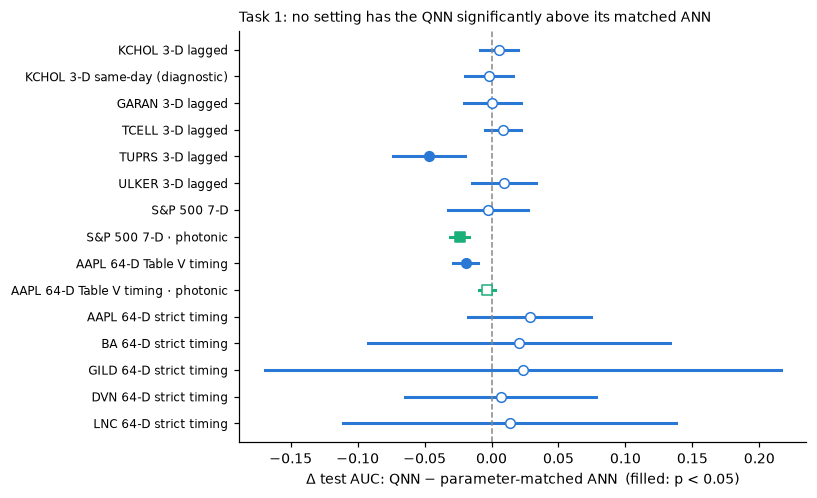

In [15]:
# STORED: every quantum − matched-control difference in Task 1 (seed-level 95% interval).
task1 = differences[differences.comparison == "leak_free:qnn - leak_free:ann_parameter_matched"].reset_index(drop=True)
fig, axis = plt.subplots(figsize=(7.5, 4.6))
for position, row in task1.iterrows():
    color = COLORS["photonic"] if "photonic" in row.model else COLORS["QNN"]
    significant = row.p_value < 0.05
    axis.plot([row.ci_low, row.ci_high], [position, position], color=color, linewidth=2)
    axis.scatter(row.difference, position, color=color if significant else "white", edgecolor=color, s=40, zorder=3,
                 marker="s" if "photonic" in row.model else "o")
axis.axvline(0, color="#888888", linestyle="--", linewidth=1)
axis.set_yticks(range(len(task1)), [f"{s}{' · photonic' if 'photonic' in m else ''}" for s, m in zip(task1.setting, task1.model)], fontsize=8)
axis.invert_yaxis()
axis.set_xlabel("Δ test AUC: QNN − parameter-matched ANN  (filled: p < 0.05)")
axis.set_title("Task 1: no setting has the QNN significantly above its matched ANN", fontsize=9, loc="left")
fig.tight_layout()
plt.show()

**Observation.**
- Across 12 qubit settings, no interval lies entirely above 0.
- Two lie entirely below 0: TUPRS, and AAPL under the Table V timing.
- The quantum models also cost 20–150× more simulated wall-clock per training.

**Inference.** Against controls matched in parameters, data, protocol and seeds, the paper's quantum models never win, and they are more expensive.

**Remaining uncertainty.**
- The tuning budget is **not** matched in T1. It favours the QNN, which strengthens the negative result.
- The wall-clock compares simulations, not hardware.

**Claim impact.** C11 ("the benchmark is fair") is **not supported**, and none of C1, C2, C5 or C7 survives against fair controls.

<a id="9"></a>
## 9. Controls and ablations

These controls test **alternative explanations** for the paper's numbers. Each one is a **LIVE** recomputation from the raw data with `lib/`, checked against the stored sweep.

### 9.1 Leakage control for KCHOL (explains C2)

**Alternative explanation.**
- RSI and %K at day *t* use the close $P_t$, and the label is $1[P_t > P_{t-1}]$.
- If the paper's indicators were computed on day *t* rather than *t − 1*, the features contain the answer.
- **Prediction:** with same-day indicators, even a logistic regression should jump far above chance.

In [16]:
# LIVE: logistic regression, fitted exactly as in the runner (fold-5 train + early-stop rows, min-max on train).
def fold5_logistic_auc(dataset_cfg):
    frame = data.build_directional_frame(dataset_cfg, DATA_ROOT)
    test_fold = data.walk_forward_folds(frame.index, dataset_cfg)[-1]
    values, labels = frame.drop(columns="label").to_numpy(), frame["label"].to_numpy()
    scaled = data.MinMaxScaler().fit(values[test_fold.train]).transform(values)
    fit_rows = np.concatenate([test_fold.train, test_fold.early_stop])
    model = LogisticRegression(max_iter=1000).fit(scaled[fit_rows], labels[fit_rows])
    return metrics.safe_auc(labels[test_fold.validation], model.predict_proba(scaled[test_fold.validation])[:, 1])

leak_rows = []
for timing in ["lagged", "same_day"]:
    leak_rows.append({"KCHOL 3-D indicators": timing,
                      "logistic AUC (LIVE)": fold5_logistic_auc({**kchol_dataset, "feature_timing": timing})})
leak = pd.DataFrame(leak_rows).set_index("KCHOL 3-D indicators")
same_day = per_seed[per_seed.sweep_id == "e1_kchol_sameday"].groupby("model")["auc"].mean()
lagged = per_seed[per_seed.sweep_id == "e1_kchol_2"].groupby("model")["auc"].mean()
leak["logistic AUC (STORED sweep)"] = [lagged["logistic_regression"], same_day["logistic_regression"]]
leak["QNN AUC (STORED, 5 seeds)"] = [lagged["leak_free:qnn"], same_day["leak_free:qnn"]]
leak["ANN AUC (STORED, 5 seeds)"] = [lagged["leak_free:ann"], same_day["leak_free:ann"]]
leak["paper QNN / ANN"] = "0.797 / 0.748"
leak.round(3)

,logistic AUC (LIVE),logistic AUC (STORED sweep),"QNN AUC (STORED, 5 seeds)","ANN AUC (STORED, 5 seeds)",paper QNN / ANN
KCHOL 3-D indicators,,,,,
lagged,0.498,0.498,0.516,0.511,0.797 / 0.748
same_day,0.910,0.910,0.926,0.944,0.797 / 0.748


**Observation.**
- With day-*t* indicators, AUC jumps from chance (about 0.50) to 0.91–0.94 for every model, including logistic regression. That is *above* the paper's 0.80.
- The live recomputation equals the stored sweep value.
- In the same-day setting the ANN grid beats the QNN (p = 0.021).

**Inference.**
- The paper's Turkish AUCs (0.71–0.90) are reachable only when the features include the target day's close.
- The most likely explanation is look-ahead in the original feature pipeline, perhaps partial (for example, indicators smoothed or aligned so that some same-day information enters).

**Remaining uncertainty.** The paper's exact feature code is unavailable, so the precise form of the leak is not identified.

**Claim impact.** C2 is **not reproduced**, and its evidence is most likely an artifact of leakage. Even with leakage, the QNN does not beat the ANN.

### 9.2 Feature-timing control for the U.S. 64-D set (explains C1's level)

**Alternative explanation.** The paper's Table V marks the Asian and European indices as "same day". They close before the U.S. close, so their day-*t* returns are legitimately available. Including them (lags 0–6), instead of strictly lagging all inputs (lags 1–7), should restore the paper's AAPL AUC level.

In [17]:
# LIVE: the same logistic control on AAPL 64-D, strict timing vs Table V timing.
e3_config = json.loads((PROJECT_DIR / "configs/e3_original.json").read_text())
aapl_dataset = deep_update(copy.deepcopy(defaults["directional"]["dataset"]), e3_config["directional"]["dataset"])
timing_rows = []
for timing, sweep in [("lagged", "e3_aapl"), ("table_v", "e3_tablev_aapl")]:
    stored = per_seed[per_seed.sweep_id == sweep].groupby("model")["auc"]
    timing_rows.append({"AAPL 64-D timing": timing,
                        "logistic AUC (LIVE)": fold5_logistic_auc({**aapl_dataset, "ticker": "AAPL", "feature_timing": timing}),
                        "logistic AUC (STORED)": stored.mean()["logistic_regression"],
                        "QNN (STORED, 5 seeds)": f"{stored.mean()['leak_free:qnn']:.3f} ± {stored.std()['leak_free:qnn']:.3f}",
                        "ANN (STORED, 5 seeds)": f"{stored.mean()['leak_free:ann']:.3f} ± {stored.std()['leak_free:ann']:.3f}",
                        "paper QNN / ANN": "0.635 / 0.597"})
pd.DataFrame(timing_rows).set_index("AAPL 64-D timing").round(3)

,logistic AUC (LIVE),logistic AUC (STORED),"QNN (STORED, 5 seeds)","ANN (STORED, 5 seeds)",paper QNN / ANN
AAPL 64-D timing,,,,,
lagged,0.49,0.489,0.525 ± 0.026,0.495 ± 0.021,0.635 / 0.597
table_v,0.64,0.640,0.622 ± 0.008,0.641 ± 0.001,0.635 / 0.597


**Observation.**
- Strict lagging leaves AAPL at chance level.
- The Table V timing lifts every model to 0.62–0.64, the paper's level. Logistic regression alone reaches 0.640.

**Inference.**
- The paper used same-day APAC/EU returns, which is a legitimate design.
- Under that design the classical models, the paper's under-tuned ANN excepted, beat the QNN. The paper's ANN (0.597) is 0.04 below ours on the same inputs.

**Remaining uncertainty.** The Table V timing was run for AAPL only. The BA, GILD, DVN and LNC sweep was stopped because the machine was overloaded. C3 for those tickers rests on strict timing.

**Claim impact.** C1 is **contradicted** under the paper's own likely design.

### 9.3 GARCH completion control (Task 3)

**Alternative explanation.** The QSVR "beats GARCH" because the GARCH baseline forecasts a 5-day realized variance from a one-day variance and ignores the four squared returns already observed.

In [18]:
# LIVE: deterministic T3 baselines on the S&P 500 through the production runner (seconds).
vol_config = json.loads((PROJECT_DIR / "configs/e6_original.json").read_text())
cfg = deep_update({k: v for k, v in copy.deepcopy(defaults).items() if k != "directional"}, vol_config)
cfg = deep_update(cfg, {"data_root": DATA_ROOT, "volatility": {"models": ["persistence", "har", "garch_sigma2", "garch"]}})
with tempfile.TemporaryDirectory() as run_dir:
    (Path(run_dir) / "config_snapshot.json").write_text(json.dumps(cfg))
    train_and_evaluate(cfg, Path(run_dir))
    vol_live = json.loads((Path(run_dir) / "metrics.json").read_text())
garch_table = pd.DataFrame({"QLIKE (LIVE, ^GSPC)": {m: v["qlike"] for m, v in vol_live["test"].items()}})
stored_gspc = e6_table[(e6_table.exp == "e6") & (e6_table.ticker == "GSPC")].set_index("model")["qlike"]
garch_table["QLIKE (STORED S5)"] = stored_gspc.reindex(garch_table.index)
garch_table.loc["garch_sigma2", "QLIKE (STORED S5)"] = np.nan
for model in ["qsvr_angle", "svr_rbf"]:
    garch_table.loc[model] = [np.nan, stored_gspc[model]]
garch_table.loc["PAPER garch (σ²-only)"] = [np.nan, -8.2488]
garch_table.loc["PAPER qsvr_angle"] = [np.nan, -8.2937]
print("test window:", vol_live["test_window"])
garch_table.sort_values("QLIKE (STORED S5)").round(4)

test window: ['2007-11-12', '2024-12-30']


,"QLIKE (LIVE, ^GSPC)",QLIKE (STORED S5)
garch,-8.5893,-8.5893
har,-8.5530,-8.5530
svr_rbf,NaN,-8.5519
qsvr_angle,NaN,-8.5470
persistence,-8.5180,-8.5180
PAPER qsvr_angle,NaN,-8.2937
PAPER garch (σ²-only),NaN,-8.2488
garch_sigma2,-8.4503,NaN


**Observation.**
- On the S&P 500 the paper-style σ²-only GARCH (−8.450) is worse than the QSVR (−8.547), as in the paper's Table XIII.
- Completing the GARCH with the known part of the window (−8.589) makes it the best model, ahead of every kernel method. The same holds on all four tickers: the completed GARCH is significantly better than the QSVR on ^GSPC, AAPL and GARAN.

**Inference.** "QSVR beats GARCH" is a property of an incomplete baseline, not of the quantum kernel.

**Remaining uncertainty.**
- The paper does not state its GARCH formula; σ²-only is our best reading (it reproduces the paper's ranking).
- (p, q) = (1, 1) as in the paper.

**Claim impact.** The paper's implicit "QSVR beats GARCH" is **not supported** against a complete GARCH.

### 9.4 Ablations: selection protocol and QNN family (C4)

In [19]:
# STORED: effect of the paper's test-leaking selection protocol (folds 1–5) vs ours (folds 1–4) on test AUC.
pooled = per_seed.assign(sweep=per_seed.sweep_id.replace({"e3_us_rest_seed0": "e3_us_rest", "e3_us_rest_seed12": "e3_us_rest"}))
pooled = pooled[~pooled.sweep.str.contains("merlin")]
protocol = (pooled[pooled.model.isin(["leak_free:qnn", "paper:qnn", "leak_free:ann", "paper:ann"])]
            .assign(family=lambda f: f.model.str.split(":").str[1], protocol=lambda f: f.model.str.split(":").str[0])
            .groupby(["sweep", "variant", "family", "protocol"])["auc"].mean().unstack("protocol"))
protocol["paper − leak_free"] = protocol["paper"] - protocol["leak_free"]
print(f"|paper − leak_free| test AUC over {len(protocol)} (setting, family) cells: "
      f"mean {protocol['paper − leak_free'].abs().mean():.3f}, max {protocol['paper − leak_free'].abs().max():.3f}")

# Which settings show the QNN significantly above its parameter-matched ANN (seed-level t-test), per protocol?
from scipy import stats
significance = []
for (sweep, variant), group in pooled.groupby(["sweep", "variant"]):
    by_model = group.pivot_table(index="seed", columns="model", values="auc")
    for protocol_name in ["leak_free", "paper"]:
        delta = by_model[f"{protocol_name}:qnn"] - by_model[f"{protocol_name}:ann_parameter_matched"]
        p_value = stats.ttest_1samp(delta, 0).pvalue
        significance.append({"setting": f"{sweep}:{variant}", "protocol": protocol_name, "QNN − matched ANN": delta.mean(),
                             "p": p_value, "QNN significantly better": bool(delta.mean() > 0 and p_value < 0.05)})
significance = pd.DataFrame(significance)
display(significance.groupby("protocol")["QNN significantly better"].sum().rename("settings where QNN > matched ANN (p < 0.05)").to_frame())
display(significance[significance["QNN significantly better"]].round(4).reset_index(drop=True))

# STORED: C4 — best validation AUC per QNN family (leak_free folds 1–4), mean over seeds, from the exported candidate tables.
family_rows = []
for sweep in ["e1_kchol_2", "e2_spx", "e3_tablev_aapl"]:
    candidates = pd.read_csv(RESULTS / "sweep_candidates" / f"{sweep}.csv")
    best = (candidates[(candidates.rule == "leak_free") & (candidates.family == "qnn")]
            .groupby(["seed", "family_detail"])["score"].max().groupby("family_detail").mean())
    family_rows.append(best.rename(sweep))
pd.DataFrame(family_rows).round(4)

|paper − leak_free| test AUC over 26 (setting, family) cells: mean 0.015, max 0.059


,settings where QNN > matched ANN (p < 0.05)
protocol,
leak_free,0
paper,4


,setting,protocol,QNN − matched ANN,p,QNN significantly better
0,e1_turkish_rest:ULKER,paper,0.0286,0.0190,True
1,e3_aapl:main,paper,0.0479,0.0109,True
2,e3_us_rest:BA,paper,0.0466,0.0256,True
3,e3_us_rest:LNC,paper,0.0362,0.0314,True


family_detail,Hybrid-MQ,Hybrid-SQ,MQ,SQ
e1_kchol_2,0.5225,0.5205,0.5223,0.5114
e2_spx,0.7860,0.7853,0.7862,0.7816
e3_tablev_aapl,0.6448,0.6483,0.6097,0.5549


**Observation.**
- The test-leaking selection shifts test AUC by about 0.015 on average. On chance-level settings the shift reaches 0.06 (BA, ANN), almost always upward.
- Under our `leak_free` protocol, **no** setting has the QNN significantly above its parameter-matched ANN.
- Under the paper's protocol, **four chance-level settings do**: ULKER, AAPL strict timing, BA and LNC.
- QNN families on validation scores:
  - **64-D AAPL:** the hybrid families lead clearly (0.645–0.648 against 0.555–0.610), because non-hybrid amplitude models are restricted to 6 qubits.
  - **7-D S&P 500:** all four families are within 0.005.
  - **KCHOL:** all four are at chance.

**Inference.**
- The selection leak is small on average but **manufactures apparent QNN wins**. The QNN is selected on folds that include the test window, while the matched ANN is fixed by the QNN's parameter count and gets no selection benefit.
- The larger QNN grid (24–72 candidates against 10 ANN widths) gives it more chances to fit test-window noise.
- This shows why the paper's protocol (C11) is not a fair basis for "QNN beats ANN" statements.
- Hybrid preprocessing matters on 64-D inputs, which is consistent with C4's direction.

**Remaining uncertainty.**
- Only the *selected* models were evaluated on the test set, so C4 cannot be tested on test data from these runs.
- The tie-rule-free t-tests here use 3–5 seeds.

**Claim impact.**
- C4 remains **unresolved** (validation-level evidence only).
- C11 is further **weakened**: the paper's own protocol can turn chance-level ties into apparent quantum wins.

<a id="10"></a>
## 10. Robustness and uncertainty

### 10.1 The trading null band (why single-run Sharpe ratios cannot rank models)

**Alternative explanation for the paper's Sharpe differences: noise.** We feed **uniformly random scores** through exactly the paper's pipeline:
- τ calibration on the same slice;
- the same fee;
- a backtest over the whole regime.

The resulting Sharpe distribution is what a model with *no* skill achieves.

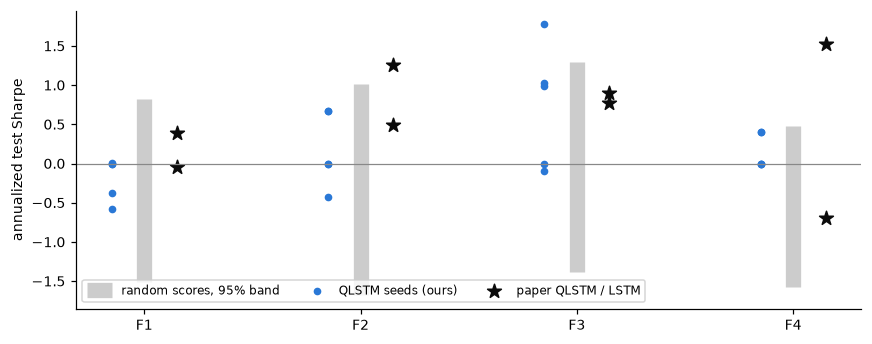

,"95% band (LIVE, 300 draws)","95% band (STORED, 2,000 draws)",paper QLSTM percentile in null
F1,"[-1.51, 0.83]","[-1.45, 0.89]",0.8785
F2,"[-1.68, 1.01]","[-1.61, 0.82]",0.9945
F3,"[-1.38, 1.29]","[-1.48, 1.04]",0.9295
F4,"[-1.58, 0.48]","[-1.58, 0.52]",0.4085


In [20]:
# LIVE: 300 random-score draws per regime through lib/tasks/trading.py (the stored diagnostic used 2,000).
import diagnose_gaps
null = diagnose_gaps.trading_null(draws=300)
stored_null = json.loads((RESULTS / "gap_trading_null.json").read_text())
fig, axis = plt.subplots(figsize=(8, 3.2))
for position, regime in enumerate(["F1", "F2", "F3", "F4"]):
    low, high = null[regime]["null_sharpe_quantiles"]["0.025"], null[regime]["null_sharpe_quantiles"]["0.975"]
    axis.plot([position, position], [low, high], color="#cccccc", linewidth=10, solid_capstyle="butt",
              label="random scores, 95% band" if position == 0 else None)
    ours = trading[(trading.regime == regime) & (trading.model == "auc:qlstm")]["sharpe"]
    axis.scatter(np.full(len(ours), position - 0.15), ours, color=COLORS["QNN"], s=16, label="QLSTM seeds (ours)" if position == 0 else None)
    axis.scatter([position + 0.15] * 2, paper_sharpe[regime], marker="*", s=90, color=COLORS["paper"], label="paper QLSTM / LSTM" if position == 0 else None)
axis.set_xticks(range(4), ["F1", "F2", "F3", "F4"])
axis.set_ylabel("annualized test Sharpe")
axis.axhline(0, color="#888888", linewidth=0.8)
axis.legend(fontsize=8, loc="lower left", ncol=3)
fig.tight_layout()
plt.show()
pd.DataFrame({regime: {"95% band (LIVE, 300 draws)": f"[{null[regime]['null_sharpe_quantiles']['0.025']:.2f}, {null[regime]['null_sharpe_quantiles']['0.975']:.2f}]",
                       "95% band (STORED, 2,000 draws)": f"[{stored_null[regime]['null_sharpe_quantiles']['0.025']:.2f}, {stored_null[regime]['null_sharpe_quantiles']['0.975']:.2f}]",
                       "paper QLSTM percentile in null": stored_null[regime]["paper_qlstm_sharpe_percentile"]}
              for regime in ["F1", "F2", "F3", "F4"]}).T

**Observation.**
- Random scores give 95% Sharpe bands from about −1.5 up to +0.5 (F4) to +1.0 (F3), depending on the regime.
- Almost every paper and local value lies inside that band. The exceptions are the paper's F2 QLSTM (above about the 99th percentile) and F4 LSTM (above the band).

**Inference.** A single run cannot distinguish a skilled model from a lucky draw at these magnitudes. The paper's QLSTM-vs-LSTM rankings are within the noise of its own protocol.

**Remaining uncertainty.** The null band assumes independent scores. Real models produce autocorrelated scores, which could widen it further.

**Claim impact.** C5 is **not supported**: the evidence cannot carry it even in principle without many seeds.

### 10.2 Seed spread and tuning-seed limitations

- **T1:** 5 seeds for KCHOL, S&P 500 and AAPL; 3 seeds for BA, GILD, DVN and LNC. Every seed is shown in Sections 7–8, and every sweep's run count was verified against its plan (`results/sweep_index.csv`).
- **T2:** 5 seeds, but selection on seed 0 only (`partial`).
- **T3:** one Optuna sampler seed (`preliminary`). The DM tests capture forecast noise, not tuner noise.

In [21]:
# STORED: completeness of every sweep used above (expected vs completed runs; ties decided by the tie rule).
pd.read_csv(RESULTS / "sweep_index.csv")[["sweep_id", "task", "expected_runs", "completed_runs", "completeness", "selections_decided_by_tie_rule"]]

,sweep_id,task,expected_runs,completed_runs,completeness,selections_decided_by_tie_rule
0,e1_kchol_2,directional,5,5,COMPLETE,0
1,e1_kchol_sameday,directional,5,5,COMPLETE,1
2,e3_aapl,directional,5,5,COMPLETE,0
3,e2_spx,directional,5,5,COMPLETE,1
4,e1_turkish_rest,directional,20,20,COMPLETE,5
5,e3_us_rest_seed0,directional,4,4,COMPLETE,0
6,e3_us_rest_seed12,directional,8,8,COMPLETE,0
7,e3_tablev_aapl,directional,5,5,COMPLETE,1
8,e6_e7_seed0,volatility,8,8,COMPLETE,0
9,e6_garch_sigma2,volatility,4,4,COMPLETE,0


<a id="11"></a>
## 11. Photonic assessment with MerLin (an `adaptation`, not the paper's method)

**Question.** Does a photonic (linear-optics) version of the paper's quantum models change the picture? We keep each model's **scientific role**:
- **Kernel (T3).** A fixed quantum feature-space kernel inside an SVR. Photonic version: 10 modes, 2–3 single photons, phases $\pi x$ re-uploaded after fixed random Mach–Zehnder meshes. The kernel is the exact multi-photon fidelity $|\langle\psi(x)|\psi(x')\rangle|^2$ from FOCK-space amplitudes.
- **Classifier (T1).** A trainable quantum classifier against capacity-matched classical models. Photonic version: trainable meshes with threshold-detector (UNBUNCHED) readout. SQ′ reads P(last mode occupied); MQ′ applies a linear head over the outcomes.

**Not translated, and why.**
- QLSTM: the trading protocol cannot separate models (Section 10).
- Amplitude QSVR: it is a classical kernel on any platform (Section 4).

All MerLin runs are noiseless, analytic simulations. The package is `merlinquantum` 0.4.2, although `merlin.__version__` reports 0.4.1.

input state (10 modes, 3 photons): [1, 0, 0, 1, 0, 0, 0, 1, 0, 0]
FOCK dimension: 220 (= C(12, 3)); Gram symmetric: True; min eigenvalue: 2.64e-02
correlation of off-diagonal entries, photonic vs qubit kernel: 0.480


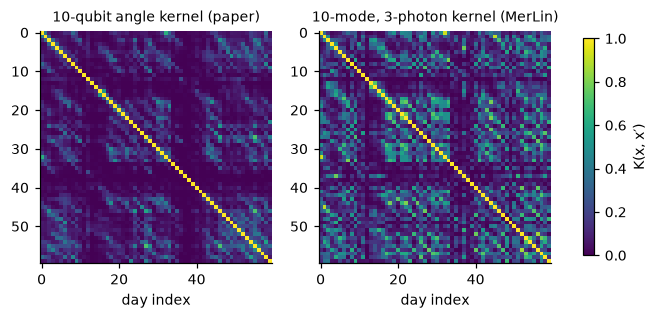

In [22]:
# LIVE: photonic fidelity kernel on 60 S&P 500 volatility feature vectors, compared with the 10-qubit angle kernel.
from lib.photonic_merlin import photonic_feature_states, spread_input_state

vol_frame = data.build_volatility_frame(vol_config["volatility"]["dataset"], DATA_ROOT)
vol_features = vol_frame[data.volatility_feature_columns(vol_config["volatility"]["dataset"])].to_numpy()[:60]
vol_unit = (vol_features - vol_features.min(0)) / (vol_features.max(0) - vol_features.min(0))
print("input state (10 modes, 3 photons):", spread_input_state(10, 3))
photonic_states = photonic_feature_states(vol_unit, n_photons=3, layers=1, angle_scale=np.pi, mesh_seed=1234)
photonic_gram = kernels.fidelity_kernel(photonic_states, photonic_states)
qubit_gram = kernels.fidelity_kernel(*(kernels.angle_feature_states(vol_unit, 1, "ring", np.pi, 1234),) * 2)
upper = np.triu_indices(60, 1)
print(f"FOCK dimension: {photonic_states.shape[1]} (= C(12, 3)); Gram symmetric: {np.allclose(photonic_gram, photonic_gram.T)}; "
      f"min eigenvalue: {np.linalg.eigvalsh(photonic_gram).min():.2e}")
print(f"correlation of off-diagonal entries, photonic vs qubit kernel: {np.corrcoef(photonic_gram[upper], qubit_gram[upper])[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
for axis, gram, title in zip(axes, [qubit_gram, photonic_gram], ["10-qubit angle kernel (paper)", "10-mode, 3-photon kernel (MerLin)"]):
    image = axis.imshow(gram, vmin=0, vmax=1, cmap="viridis")
    axis.set_title(title, fontsize=9)
    axis.set_xlabel("day index")
fig.colorbar(image, ax=axes, shrink=0.8, label="K(x, x′)")
plt.show()

In [23]:
# LIVE: why the code passes π·x explicitly — CircuitBuilder.add_angle_encoding(scale=...) has no effect in MerLin 0.4.x.
from merlin_feedback_reproducers import FOUR_MODE_STATE, make_builder, quantum_layer
inputs = torch.rand(3, 4, dtype=torch.float64)
with torch.no_grad():
    scaled = quantum_layer(make_builder(4, True, scale=np.pi), FOUR_MODE_STATE, amplitudes=False)(inputs)
    unscaled = quantum_layer(make_builder(4, True), FOUR_MODE_STATE, amplitudes=False)(inputs)
print(f"max |P(scale=π) − P(scale=1)| = {float((scaled - unscaled).abs().max()):.1e}   (non-zero would mean scale is applied)")

max |P(scale=π) − P(scale=1)| = 0.0e+00   (non-zero would mean scale is applied)


In [24]:
# STORED: photonic results (sweeps S13–S15) against the qubit models and the fair controls.
merlin_vs_qubit = pd.read_csv(RESULTS / "e6_merlin_vs_qubit.csv").pivot(index="model", columns="ticker", values="qlike")
t3 = merlin_vs_qubit.loc[["photonic_kernel", "qsvr_angle", "svr_rbf", "garch"], ["GSPC", "AAPL", "GARAN", "KCHOL"]]
display(t3.round(3).rename_axis("T3 test QLIKE (lower is better)"))

t1_rows = []
for sweep, setting in [("e2_merlin", "S&P 500 7-D"), ("e3_tablev_merlin", "AAPL 64-D Table V")]:
    photonic = per_seed[per_seed.sweep_id == sweep].groupby("model")["auc"]
    qubit = per_seed[per_seed.sweep_id == {"e2_merlin": "e2_spx", "e3_tablev_merlin": "e3_tablev_aapl"}[sweep]].groupby("model")["auc"]
    parameters = per_seed[(per_seed.sweep_id == sweep) & (per_seed.model == "leak_free:qnn")]["parameters"]
    t1_rows.append({"setting": setting,
                    "photonic QNN (5 seeds)": f"{photonic.mean()['leak_free:qnn']:.3f} ± {photonic.std()['leak_free:qnn']:.3f}",
                    "photonic parameters": f"{parameters.min()}–{parameters.max()}",
                    "paired matched ANN": f"{photonic.mean()['leak_free:ann_parameter_matched']:.3f}",
                    "logistic": f"{photonic.mean()['logistic_regression']:.3f}",
                    "qubit QNN (5 seeds)": f"{qubit.mean()['leak_free:qnn']:.3f} ± {qubit.std()['leak_free:qnn']:.3f}"})
display(pd.DataFrame(t1_rows).set_index("setting"))
(differences[differences.model.str.contains("photonic")][["setting", "model", "comparison", "difference", "p_value"]]
 .round(4).reset_index(drop=True))

ticker,GSPC,AAPL,GARAN,KCHOL
T3 test QLIKE (lower is better),,,,
photonic_kernel,-8.544,-7.365,-6.668,-7.003
qsvr_angle,-8.547,-7.380,-6.704,-7.008
svr_rbf,-8.552,-7.382,-6.706,-7.026
garch,-8.590,-7.400,-6.713,-7.030


,photonic QNN (5 seeds),photonic parameters,paired matched ANN,logistic,qubit QNN (5 seeds)
setting,,,,,
S&P 500 7-D,0.745 ± 0.005,140–182,0.769,0.767,0.757 ± 0.008
AAPL 64-D Table V,0.635 ± 0.004,450–688,0.638,0.640,0.622 ± 0.008


,setting,model,comparison,difference,p_value
0,S&P 500 7-D,photonic QNN (MerLin adaptation),leak_free:qnn - leak_free:ann,-0.0123,0.2159
1,S&P 500 7-D,photonic QNN (MerLin adaptation),leak_free:qnn - leak_free:ann_parameter_matched,-0.0239,0.0009
2,S&P 500 7-D,photonic QNN (MerLin adaptation),leak_free:qnn - logistic_regression,-0.0225,0.0007
3,AAPL 64-D Table V timing,photonic QNN (MerLin adaptation),leak_free:qnn - leak_free:ann,-0.0059,0.0626
4,AAPL 64-D Table V timing,photonic QNN (MerLin adaptation),leak_free:qnn - leak_free:ann_parameter_matched,-0.0034,0.1933
5,AAPL 64-D Table V timing,photonic QNN (MerLin adaptation),leak_free:qnn - logistic_regression,-0.0046,0.0695
6,RV AAPL,photonic kernel,QLIKE(qsvr_angle) - QLIKE(photonic_kernel); ne...,-0.0157,0.0001
7,RV GARAN,photonic kernel,QLIKE(qsvr_angle) - QLIKE(photonic_kernel); ne...,-0.0362,0.0513
8,RV GSPC,photonic kernel,QLIKE(qsvr_angle) - QLIKE(photonic_kernel); ne...,-0.0038,0.2886
9,RV KCHOL,photonic kernel,QLIKE(qsvr_angle) - QLIKE(photonic_kernel); ne...,-0.0056,0.7253


**Hardware-aware settings (all executed MerLin results).**

| Field | Kernel (S13) | QNN, S&P 500 (S14) | QNN, AAPL (S15) |
|---|---|---|---|
| Photons / modes | 2–3 / 10 | 2–3 / 7 | 2 / 6–8 |
| Input state | spread single photons, e.g. [1,0,0,1,0,0,0,1,0,0] | [1,0,1,0,0,1,0] or [1,0,0,0,1,0,0] | [1,0,0,1,0,0] or [1,0,0,0,1,0,0,0] |
| Computation space / detector | FOCK amplitudes, exact overlap (hardware: threshold detection of the input pattern) | UNBUNCHED, threshold detectors | UNBUNCHED, threshold detectors |
| Shots / noise / postselection | analytic / none / none | analytic / none / none | analytic / none / none |
| Seeds and wall-clock | Optuna seed 0; 14 min for 4 runs | 0–4; 2 h 36 min | 0–4; 2 h 23 min |

**Observation.**
- The photonic and qubit kernels are **different feature maps**: on 60 days their off-diagonal entries correlate only moderately (about 0.5).
- Yet after tuning, the photonic QSVR's QLIKE is within 0.02 of the qubit QSVR on 3/4 tickers (GARAN +0.036). Both are behind the completed GARCH and RBF.
- The photonic QNNs are within 0.015 AUC of the qubit QNNs. On AAPL they reach that with 4–8× fewer parameters.
- No photonic model is significantly better than any matched control. On E2 the photonic QNN is significantly *below* its matched ANN (−0.024, p = 0.0009).

**Inference.**
- Moving from qubits to photons preserves the paper models' standing relative to classical baselines: comparable, never better.
- That two quite different kernels give nearly the same forecasts suggests the forecast is limited by the signal in the inputs, not by the feature space.

**Remaining uncertainty.**
- The photonic grids are smaller than the qubit grids.
- The kernel uses a single tuning seed.
- There is no hardware noise or loss.

**Claim impact (extension).** There is **no photonic advantage** on any in-scope task. MerLin issues found along the way were reported to the MerLin team with reproducers.

<a id="12"></a>
## 12. Claim-level conclusion

### Separating the outcomes

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | Yes. Sanity checks pass, and the live E2, leakage, timing, GARCH, null-band and photonic cells run | §4, §6, §9, §10, §11 |
| Does the method solve the task? | Only where the inputs carry signal: S&P 500 (AUC 0.76), AAPL with Table V timing (0.62), volatility (all models). Elsewhere every model is at chance | §7 |
| Does the paper's metric reproduce? | For Table X and AAPL's level (Table V timing), and Table XIII's QSVR ≈ RBF closeness. Not for the Turkish or strictly lagged U.S. AUCs, the Sharpe values, or absolute QLIKE | §7.2–7.4 |
| Does the paper's explanation survive controls? | No. Turkish levels need same-day leakage; "beats GARCH" needs an incomplete GARCH; Sharpe gaps sit inside the random-score band | §9, §10 |
| Does the quantum method beat a fair baseline? | No, in any setting. Classical controls are significantly better on AAPL, TUPRS and (vs completed GARCH) three volatility tickers | §8, §9.3 |

### 1. What reproduced
- **S&P 500 direction, Table X:** QNN 0.757 ± 0.008 and ANN 0.757 ± 0.012, against the paper's 0.750 / 0.766 (§6, §7.1).
- **AAPL's AUC level under the Table V timing:** QNN 0.622 vs the paper's 0.635 (§7.1, §9.2).
- **"QSVR within 0.02–0.04 of RBF"** on ^GSPC and AAPL (§7.4).
- **The four QLSTM parameter counts** of Table XII, exactly (§4).
- **The S&P 500 Table VI statistics** (§2).

### 2. What did not reproduce
- **C1 (AAPL):** the classical models beat the QNN, −0.019 AUC, p = 0.005 (§7.1, §8).
- **C2 (KCHOL) and the Turkish AUCs:** chance level with leak-free features (§7.1, §9.1).
- **C5/C6 (QLSTM Sharpe and AUC):** ties in all regimes (§7.3, §10.1).
- **C7 (QSVR lowest on KCHOL):** not supported (§7.4).
- **"QSVR beats GARCH"** against a complete GARCH (§9.3).
- **C11 (fair benchmark):** not supported. The paper's selection protocol alone turns four chance-level ties into apparent QNN wins (§8, §9.4).

### 3. What remains unresolved
- **C4:** the per-family effect on test data (§9.4).
- **The exact form of the paper's same-day leakage** (§9.1).
- **The paper's Task 3 test window**, so absolute QLIKE levels are not comparable (§7.4).
- **C3 under the Table V timing** for BA, GILD, DVN and LNC (§9.2).

### 4. What was not attempted
- E8: the amplitude QSVR at d = 16/64 and training-window robustness. C9's "degrades at d = 64" is untested.
- Optuna seeds beyond the first for Task 3.
- A full grid search per seed for Task 2.
- Hardware (QPU) execution.

### 5. Reproduction verdict
**Partially reproduced.** The paper's pipeline and several metric levels are recovered. **None of its quantum-advantage claims survive** leak-free features, multiple seeds and fair, parameter-matched classical controls.

| Claim | Verdict |
|---|---|
| C1 | Unsupported |
| C2 | Unsupported |
| C3 | Partially supported |
| C4 | Unresolved |
| C5 | Unsupported |
| C6 | Unsupported |
| C7 | Unsupported |
| C8 | Partially supported |
| C9 | Partially supported |
| C10 | Supported (single tuning seed) |
| C11 | Unsupported |

### 6. Extension (photonic) verdict
**`PARTIAL_MERLIN_TRANSLATION`, no photonic advantage.** MerLin kernels and classifiers match the qubit models and never beat the fair classical baselines (§11).

### Limitations

**Reduced budgets:**
- Task 2 is `partial` (seed-0 selection).
- Task 3 is `preliminary` (one tuning seed).
- The live cells in this notebook use reduced grids; the headline numbers come from the stored full sweeps.

**Data and simulation:**
- **Data:** a later Yahoo snapshot than the paper's; adjusted prices may differ for single stocks.
- **Simulation:** exact noiseless statevector (qubits) and analytic MerLin (photons); no shot noise, loss or hardware.

**Incomplete work:**
- The Table V-timing sweep for four U.S. tickers was stopped.
- E8 was not run.
- C4 was analysed on validation scores only.

**Qualitative-only support:** C4's direction (§9.4).

In [25]:
# Provenance: code revision, environment, hardware and runtime of this notebook execution.
revision = subprocess.run(["git", "-C", str(REPO_ROOT), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
dirty = bool(subprocess.run(["git", "-C", str(REPO_ROOT), "status", "--porcelain", "--", str(PROJECT_DIR)], capture_output=True, text=True).stdout.strip())
import sklearn
provenance = {
    "code revision": f"{revision}{' + uncommitted paper changes' if dirty else ''}",
    "python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__, "merlinquantum": __import__("importlib.metadata").metadata.version("merlinquantum"),
    "hardware": f"{platform.machine()} / {platform.system()} (CPU only)",
    "data snapshot": manifest["fetched_at_utc"],
    "stored evidence": "results/*.csv, results/sweep_candidates/, results/sweep_index.csv (sweeps S1–S15; S12b excluded)",
    "notebook runtime (s)": round(time.time() - NOTEBOOK_START),
}
pd.Series(provenance).to_frame("value")

,value
code revision,d4f4a3c + uncommitted paper changes
python,3.12.4
torch,2.12.1
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
merlinquantum,0.4.2
hardware,arm64 / Darwin (CPU only)
data snapshot,2026-10-21T08:32:15+00:00
stored evidence,"results/*.csv, results/sweep_candidates/, resu..."
